# NN-Interp: learning multiplication

We train a small **2 → 4 → 2 → 1** network (25 trainable parameters) on independent uniform inputs in $[-2, 2]^2$, with target $xy$. Both hidden layers use `tanh`; the output is linear. Our goal is **held-out MSE < 0.001**.

We plot the learned surface at several training stages, print five activation examples from each of four cases, and fit **4 → 1** and **2 → 1** linear probes to the frozen hidden layers.

Run the cells from top to bottom. Only PyTorch and Matplotlib are required. Training uses Adam followed by full-batch L-BFGS refinement; it can take a few minutes on a CPU.

In [1]:
# Run this once if the packages are missing, then restart the kernel:
# %pip install torch matplotlib

In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt

# One thread avoids overhead for these tiny matrices.
torch.set_num_threads(1)
torch.manual_seed(42)
plt.rcParams["figure.figsize"] = (8, 4)


def sample_inputs(n, generator=None):
    return 4 * torch.rand(n, 2, generator=generator) - 2


def product(inputs):
    return inputs[:, :1] * inputs[:, 1:2]


train_x = sample_inputs(4096)
validation_x = sample_inputs(4096)
# An independent generator keeps the final test set separate from tuning.
test_x = sample_inputs(16384, generator=torch.Generator().manual_seed(2026))
train_y = product(train_x)
validation_y = product(validation_x)
test_y = product(test_x)

## Train the multiplication network

`activations()` returns the values **after** each hidden layer's `tanh`. Adam learns the overall shape, then L-BFGS refines the same 25 parameters. Neither optimizer uses validation or test examples for its gradients.

Snapshots show MSE on a fixed held-out **validation** set used during experimentation. The independent final **test** set is evaluated after training. A random test-set MSE measures average error, not a bound on error at every input.

Step 0: held-out validation MSE = 2.357946


Adam step 100: held-out validation MSE = 0.294962


Adam step 500: held-out validation MSE = 0.026764


Adam step 2000: held-out validation MSE = 0.005740


Adam step 6000: held-out validation MSE = 0.001360


Adam step 12000: held-out validation MSE = 0.000718


After L-BFGS: held-out validation MSE = 0.000718

Parameters: 25
Final held-out test MSE: 0.000724
Final held-out test MAE: 0.019585
MSE < 0.001: True


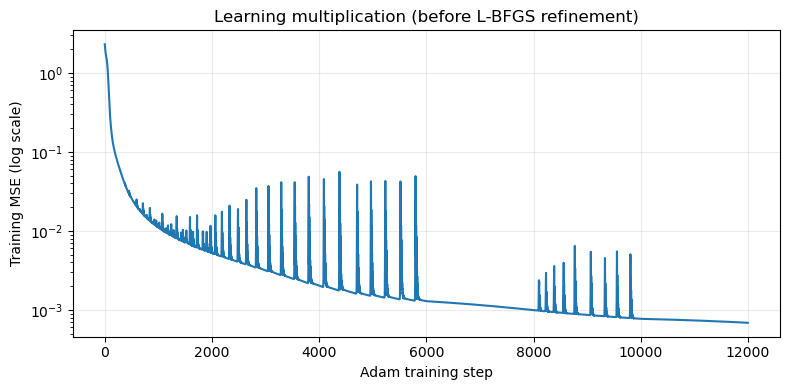

In [3]:
class MultiplicationNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden1 = nn.Linear(2, 4)
        self.hidden2 = nn.Linear(4, 2)
        self.output = nn.Linear(2, 1)

    def activations(self, inputs):
        h1 = torch.tanh(self.hidden1(inputs))
        h2 = torch.tanh(self.hidden2(h1))
        return h1, h2

    def forward(self, inputs):
        _, h2 = self.activations(inputs)
        return self.output(h2)


model = MultiplicationNet()
loss_fn = nn.MSELoss()
losses = []
snapshots = []
snapshot_steps = {0, 100, 500, 2000, 6000, 12000}
stage_axis = torch.linspace(-2, 2, 41)
stage_xx, stage_yy = torch.meshgrid(stage_axis, stage_axis, indexing="xy")
stage_grid = torch.stack([stage_xx.flatten(), stage_yy.flatten()], dim=1)


@torch.no_grad()
def save_snapshot(label):
    mse = loss_fn(model(validation_x), validation_y).item()
    surface = model(stage_grid).reshape(stage_xx.shape).clone()
    snapshots.append((label, mse, surface))
    print(f"{label}: held-out validation MSE = {mse:.6f}")


optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
scheduler = torch.optim.lr_scheduler.MultiStepLR(
    optimizer, milestones=[6000, 10000], gamma=0.3
)
model.train()
save_snapshot("Step 0")
for step in range(1, 12001):
    loss = loss_fn(model(train_x), train_y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    scheduler.step()
    losses.append(loss.item())
    if step in snapshot_steps:
        save_snapshot(f"Adam step {step}")

# Refine the fit without adding neurons or changing the activation function.
optimizer = torch.optim.LBFGS(
    model.parameters(), max_iter=1500, line_search_fn="strong_wolfe",
    tolerance_grad=1e-9, tolerance_change=1e-12,
)


def refine_closure():
    optimizer.zero_grad()
    loss = loss_fn(model(train_x), train_y)
    loss.backward()
    return loss


optimizer.step(refine_closure)
model.eval()
save_snapshot("After L-BFGS")
with torch.no_grad():
    test_prediction = model(test_x)
    test_mse = loss_fn(test_prediction, test_y).item()
    print(f"\nParameters: {sum(p.numel() for p in model.parameters())}")
    print(f"Final held-out test MSE: {test_mse:.6f}")
    print(f"Final held-out test MAE: {(test_prediction - test_y).abs().mean().item():.6f}")
    print(f"MSE < 0.001: {test_mse < 0.001}")

plt.semilogy(losses)
plt.xlabel("Adam training step")
plt.ylabel("Training MSE (log scale)")
plt.title("Learning multiplication (before L-BFGS refinement)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Watch the surface form

Each panel uses the same axes, viewing angle, and color scale. Its title gives the training stage and MSE on the **same held-out validation set**. The last panel shows the true multiplication surface for comparison.

### Early training: steps 10 and 50

This cell replays just the first 50 Adam updates with the original seed and data on a separate model. It can run after the imports without rerunning full training. It preserves the main model and random-number state. Titles show MSE on the same held-out validation set as the later-stage plots below.

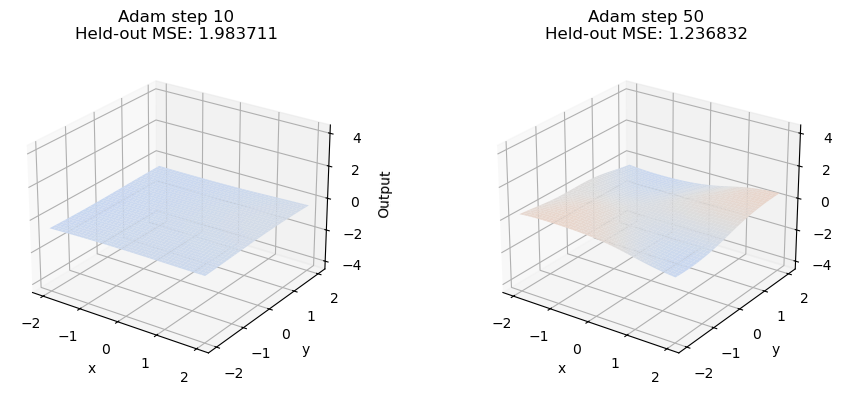

In [2]:
# Replay only 50 updates on a separate model; preserve the main model and RNG.
# This cell needs only the imports, so it can run without the long training cell.
early_snapshots = []
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(42)
    early_train_x = 4 * torch.rand(4096, 2) - 2
    early_validation_x = 4 * torch.rand(4096, 2) - 2
    early_train_y = early_train_x[:, :1] * early_train_x[:, 1:2]
    early_validation_y = early_validation_x[:, :1] * early_validation_x[:, 1:2]
    early_model = nn.Sequential(
        nn.Linear(2, 4), nn.Tanh(),
        nn.Linear(4, 2), nn.Tanh(), nn.Linear(2, 1),
    )
    early_optimizer = torch.optim.Adam(early_model.parameters(), lr=0.01)
    early_axis = torch.linspace(-2, 2, 41)
    early_xx, early_yy = torch.meshgrid(early_axis, early_axis, indexing="xy")
    early_grid = torch.stack([early_xx.flatten(), early_yy.flatten()], dim=1)

    for step in range(1, 51):
        early_loss = nn.functional.mse_loss(early_model(early_train_x), early_train_y)
        early_optimizer.zero_grad()
        early_loss.backward()
        early_optimizer.step()
        if step in (10, 50):
            with torch.no_grad():
                mse = nn.functional.mse_loss(
                    early_model(early_validation_x), early_validation_y
                ).item()
                surface = early_model(early_grid).reshape(early_xx.shape).clone()
                early_snapshots.append((step, mse, surface))

fig = plt.figure(figsize=(10, 4))
for i, (step, mse, surface) in enumerate(early_snapshots):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    ax.plot_surface(early_xx.numpy(), early_yy.numpy(), surface.numpy(),
                    cmap="coolwarm", vmin=-4, vmax=4, linewidth=0)
    ax.set(xlabel="x", ylabel="y", zlabel="Output", zlim=(-4.5, 4.5),
           title=f"Adam step {step}\nHeld-out MSE: {mse:.6f}")
    ax.view_init(elev=25, azim=-55)
plt.tight_layout()
plt.show()

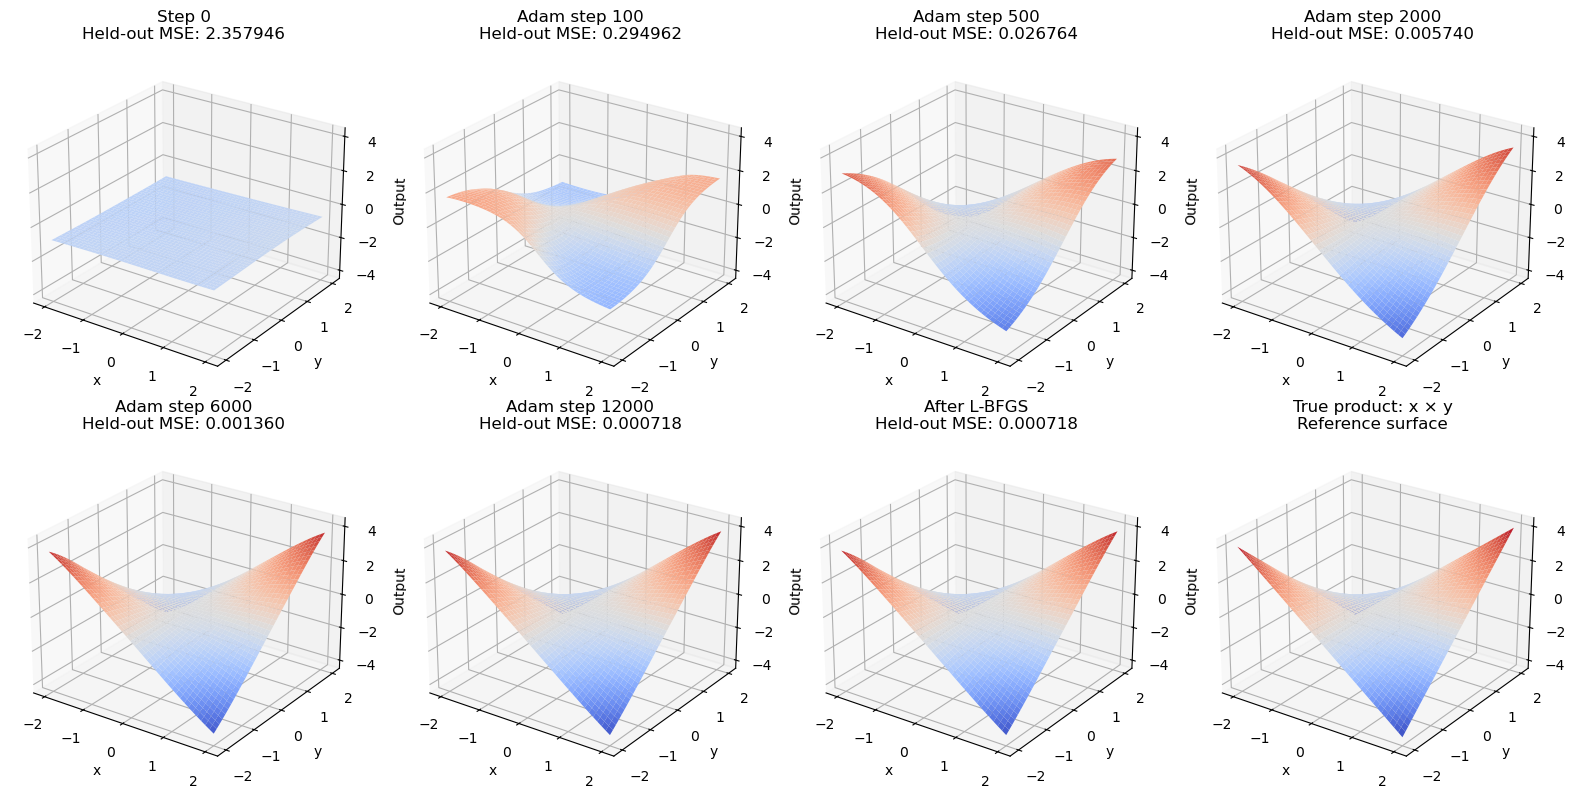

In [4]:
fig = plt.figure(figsize=(16, 8))
for i, (label, mse, surface) in enumerate(snapshots):
    ax = fig.add_subplot(2, 4, i + 1, projection="3d")
    ax.plot_surface(stage_xx.numpy(), stage_yy.numpy(), surface.numpy(),
                    cmap="coolwarm", vmin=-4, vmax=4, linewidth=0)
    ax.set(xlabel="x", ylabel="y", zlabel="Output", zlim=(-4.5, 4.5),
           title=f"{label}\nHeld-out MSE: {mse:.6f}")
    ax.view_init(elev=25, azim=-55)

ax = fig.add_subplot(2, 4, 8, projection="3d")
ax.plot_surface(stage_xx.numpy(), stage_yy.numpy(),
                (stage_xx * stage_yy).numpy(), cmap="coolwarm",
                vmin=-4, vmax=4, linewidth=0)
ax.set(xlabel="x", ylabel="y", zlabel="Output", zlim=(-4.5, 4.5),
       title="True product: x × y\nReference surface")
ax.view_init(elev=25, azim=-55)
plt.tight_layout()
plt.show()

## Inspect the four cases

1. Both inputs are in $[-1, 1]$.
2. Both inputs are in $[-2, -1] \cup [1, 2]$ (sample signs independently).
3. $x = 0$, with $y$ uniform on $[-2, 2]$.
4. $y = 0$, with $x$ uniform on $[-2, 2]$.

These cases are diagnostic slices, not a partition of the whole square: mixed inner/outer inputs are still included in training and the overall test set. The origin belongs to both zero-input slices.

Activation signs, saturation near ±1, and changes under input sign flips may suggest patterns. A neuron's activation alone does not establish what computation it performs.

In [3]:
def make_cases(n, seed):
    generator = torch.Generator().manual_seed(seed)
    inner = 2 * torch.rand(n, 2, generator=generator) - 1
    signs = 2 * torch.randint(0, 2, (n, 2), generator=generator) - 1
    outer = signs * (1 + torch.rand(n, 2, generator=generator))
    x_zero = 4 * torch.rand(n, 2, generator=generator) - 2
    x_zero[:, 0] = 0
    y_zero = 4 * torch.rand(n, 2, generator=generator) - 2
    y_zero[:, 1] = 0
    return {"Both inner": inner, "Both outer": outer,
            "x = 0": x_zero, "y = 0": y_zero}


def vector_string(values):
    return "[" + ", ".join(f"{v:+.3f}" for v in values.tolist()) + "]"


examples = make_cases(5, seed=123)
with torch.no_grad():
    for name, inputs in examples.items():
        h1, h2 = model.activations(inputs)
        predictions = model(inputs)
        print(f"\n{name}")
        for i in range(len(inputs)):
            print(f"x={inputs[i, 0]:+.3f}  y={inputs[i, 1]:+.3f}  "
                  f"xy={product(inputs)[i, 0]:+.3f}  pred={predictions[i, 0]:+.3f}")
            print(f"  h1={vector_string(h1[i])}  h2={vector_string(h2[i])}")


Both inner
x=-0.408  y=+0.033  xy=-0.014  pred=-0.059
  h1=[-0.193, -0.523, +0.074, -0.875]  h2=[+0.043, -0.251]
x=-0.497  y=+0.377  xy=-0.187  pred=-0.225
  h1=[-0.136, -0.535, +0.223, -0.836]  h2=[-0.035, -0.137]
x=-0.852  y=+0.733  xy=-0.625  pred=-0.620
  h1=[-0.072, -0.508, +0.441, -0.741]  h2=[-0.160, +0.014]
x=-0.727  y=-0.795  xy=+0.578  pred=+0.585
  h1=[-0.316, -0.402, -0.113, -0.906]  h2=[+0.182, -0.368]
x=-0.632  y=+0.453  xy=-0.286  pred=-0.314
  h1=[-0.121, -0.520, +0.291, -0.811]  h2=[-0.070, -0.089]

Both outer
x=+1.854  y=+1.593  xy=+2.953  pred=+2.896
  h1=[+0.026, -0.841, -0.132, -0.936]  h2=[+0.355, -0.137]
x=-1.637  y=+1.983  xy=-3.245  pred=-3.268
  h1=[+0.148, -0.481, +0.828, -0.234]  h2=[-0.531, +0.096]
x=-1.274  y=+1.658  xy=-2.114  pred=-2.111
  h1=[+0.089, -0.513, +0.738, -0.450]  h2=[-0.407, +0.136]
x=-1.278  y=+1.857  xy=-2.373  pred=-2.402
  h1=[+0.122, -0.528, +0.769, -0.395]  h2=[-0.444, +0.137]
x=+1.899  y=-1.039  xy=-1.973  pred=-1.991
  h1=[-0.390, -

## Train linear probes on the frozen network

P1 is a **4 → 1** linear model of hidden layer 1; P2 is a **2 → 1** linear model of hidden layer 2. Their training targets are the **trained network's predictions**, not the true product. Hidden activations are detached: the multiplication network stays fixed throughout probe training.

We record training and held-out validation **fidelity MSE** after each L-BFGS optimizer update. Full-batch L-BFGS fits these small linear regressions quickly; an update may evaluate the loss several times during its line search. Both probes see the same input examples and targets. Probe validation examples are independent of probe training and the final test set.

P2 has the same form as the network's output layer, so it should reproduce the network almost exactly. P1 measures what is linearly readable before the second nonlinear layer. These fits describe the network's behavior; they are not causal explanations.

P1: weights=[+30.523, +20.565, -7.732, -13.714], bias=+5.306
  Final training fidelity MSE: 0.023402484
  Final held-out fidelity MSE: 0.022898551
P2: weights=[+8.013, +4.012], bias=+0.606
  Final training fidelity MSE: 4.8607884e-13
  Final held-out fidelity MSE: 4.8424589e-13


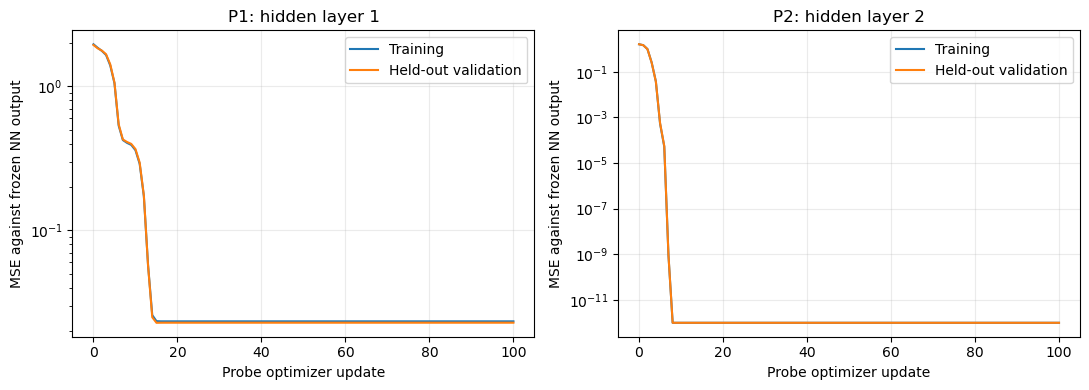

In [4]:
torch.manual_seed(7)
probe_train_x = sample_inputs(4096)
probe_validation_x = sample_inputs(4096, generator=torch.Generator().manual_seed(8))
probe_steps = 100
probe_snapshot_steps = {0, 1, 10, 100}

with torch.no_grad():
    probe_features = model.activations(probe_train_x)
    probe_targets = model(probe_train_x)
    probe_validation_features = model.activations(probe_validation_x)
    probe_validation_targets = model(probe_validation_x)


def fit_probe(features, validation_features):
    probe = nn.Linear(features.shape[1], 1)
    optimizer = torch.optim.LBFGS(
        probe.parameters(), lr=1.0, max_iter=1, max_eval=20,
        tolerance_grad=1e-10, tolerance_change=1e-12,
        line_search_fn="strong_wolfe",
    )
    history = {"train": [], "validation": []}
    states = []

    def record(step):
        with torch.no_grad():
            history["train"].append(loss_fn(probe(features), probe_targets).item())
            history["validation"].append(
                loss_fn(probe(validation_features), probe_validation_targets).item()
            )
        states.append((step, {k: v.detach().clone() for k, v in probe.state_dict().items()}))

    def closure():
        optimizer.zero_grad()
        loss = loss_fn(probe(features), probe_targets)
        loss.backward()
        return loss

    record(0)
    for step in range(1, probe_steps + 1):
        optimizer.step(closure)
        record(step)
    probe.eval()
    return probe, history, states


probe_runs = [fit_probe(train, validation) for train, validation in
              zip(probe_features, probe_validation_features)]
probe1, probe2 = [run[0] for run in probe_runs]
for name, (probe, history, _) in zip(["P1", "P2"], probe_runs):
    print(f"{name}: weights={vector_string(probe.weight.detach()[0])}, "
          f"bias={probe.bias.item():+.3f}")
    print(f"  Final training fidelity MSE: {history['train'][-1]:.8g}")
    print(f"  Final held-out fidelity MSE: {history['validation'][-1]:.8g}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name, (_, history, _) in zip(axes, ["P1: hidden layer 1", "P2: hidden layer 2"], probe_runs):
    ax.semilogy([max(v, 1e-12) for v in history["train"]], label="Training")
    ax.semilogy([max(v, 1e-12) for v in history["validation"]], label="Held-out validation")
    ax.set(title=name, xlabel="Probe optimizer update", ylabel="MSE against frozen NN output")
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

### How the probe surfaces change over the original inputs

The network has finished training; only the probe coefficients change here. For each saved probe update we evaluate $(x,y) \mapsto P(h(x,y))$. These surfaces can be curved because hidden activations are nonlinear functions of the original inputs. Titles give held-out validation fidelity MSE against the frozen network.

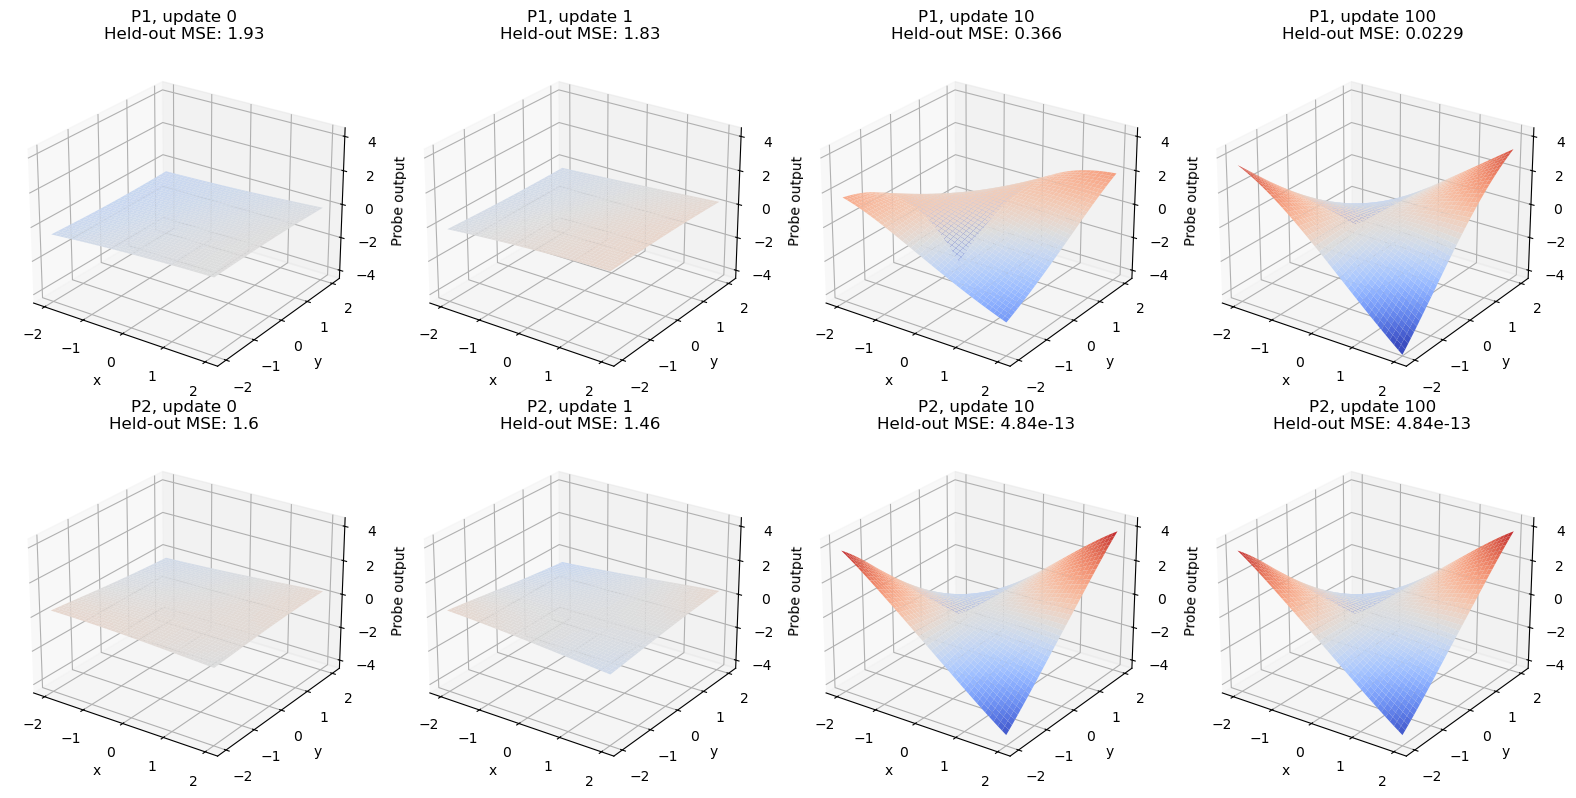

In [5]:
probe_axis = torch.linspace(-2, 2, 41)
probe_xx, probe_yy = torch.meshgrid(probe_axis, probe_axis, indexing="xy")
probe_grid = torch.stack([probe_xx.flatten(), probe_yy.flatten()], dim=1)
with torch.no_grad():
    probe_grid_features = model.activations(probe_grid)

fig = plt.figure(figsize=(16, 8))
with torch.no_grad():
    for row, ((probe, history, states), features) in enumerate(zip(probe_runs, probe_grid_features)):
        states = [item for item in states if item[0] in probe_snapshot_steps]
        for col, (step, state) in enumerate(states):
            surface = nn.functional.linear(features, state["weight"], state["bias"])
            ax = fig.add_subplot(2, 4, row * 4 + col + 1, projection="3d")
            ax.plot_surface(probe_xx.numpy(), probe_yy.numpy(),
                            surface.reshape(probe_xx.shape).numpy(),
                            cmap="coolwarm", vmin=-4, vmax=4, linewidth=0)
            ax.set(xlabel="x", ylabel="y", zlabel="Probe output", zlim=(-4.5, 4.5),
                   title=f"P{row + 1}, update {step}\nHeld-out MSE: {history['validation'][step]:.3g}")
            ax.view_init(elev=25, azim=-55)
plt.tight_layout()
plt.show()

### Probe surfaces in activation coordinates (PCA for P1)

For P1 we fit PCA **only on its training activations**, keep the top two components, and draw the plane obtained by holding the other components at their training mean. The original probe still uses all four activations; PCA is for visualization only. The reported explained variance and prediction discrepancy below indicate how much this 2D view omits. Low-variance components can still matter for prediction.

P2 already has two inputs, so its plane is exact in $(h_{2,1},h_{2,2})$ coordinates. The gray points show held-out examples at their projected coordinates, with the frozen **NN output** as height. The same PCA axes and points are used at every stage. Rectangular planes can include activation combinations the network never produces; they visualize the linear readout rather than the shape of the activation cloud.

P1 PCA variance retained: 98.13%
P1 2D-view vs full-probe prediction MSE: 1.76589


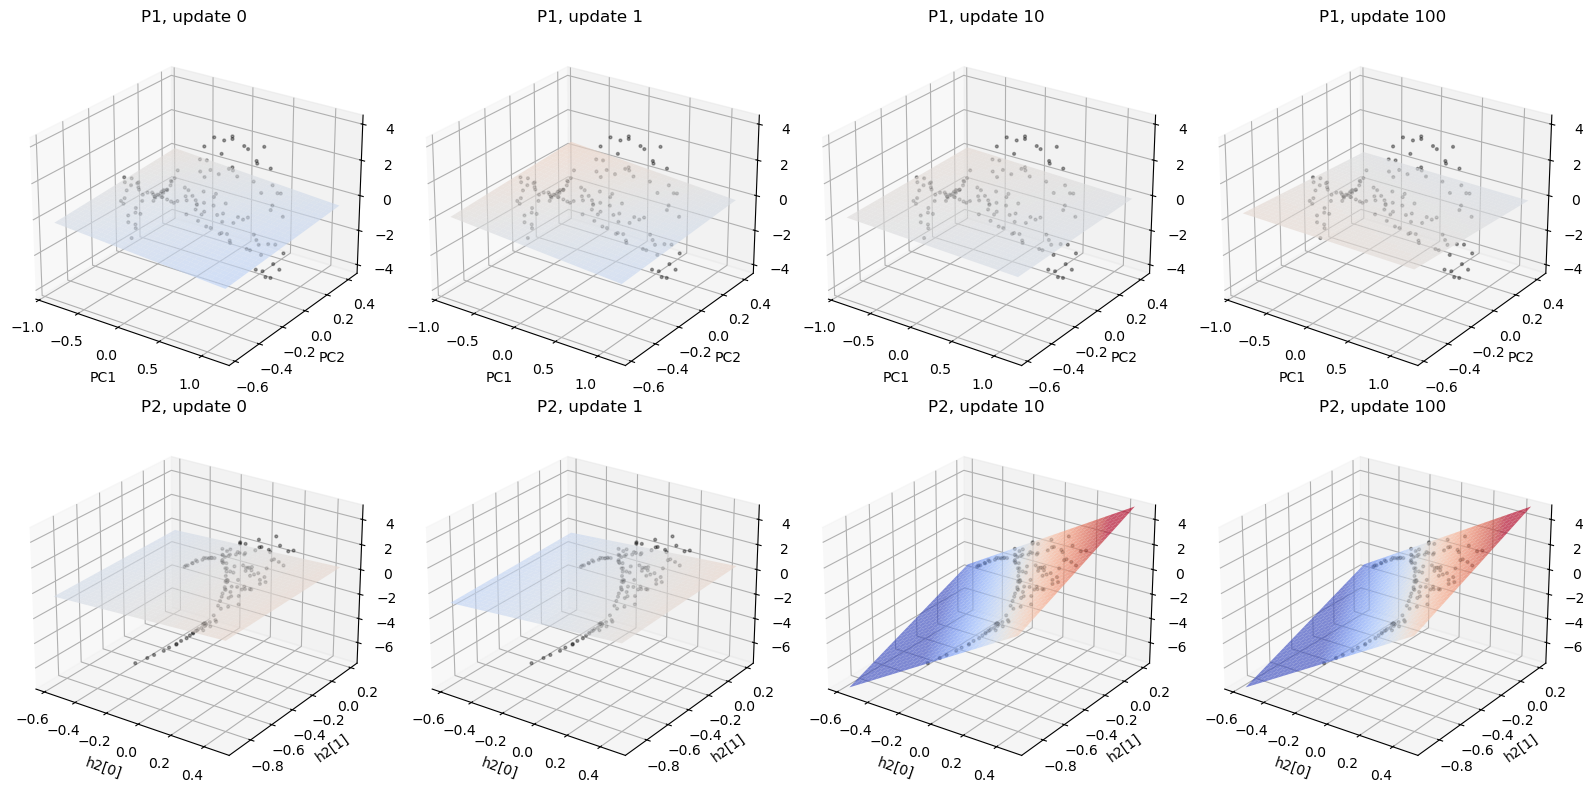

In [6]:
with torch.no_grad():
    pca_mean = probe_features[0].mean(dim=0)
    _, singular_values, vh = torch.linalg.svd(probe_features[0] - pca_mean, full_matrices=False)
    pca_basis = vh[:2].T
    explained = singular_values[:2].square().sum() / singular_values.square().sum()
    pca_train = (probe_features[0] - pca_mean) @ pca_basis
    pca_validation = (probe_validation_features[0] - pca_mean) @ pca_basis
    reconstructed_validation = pca_validation @ pca_basis.T + pca_mean
    discrepancy = loss_fn(probe1(reconstructed_validation), probe1(probe_validation_features[0]))
    print(f"P1 PCA variance retained: {100 * explained.item():.2f}%")
    print(f"P1 2D-view vs full-probe prediction MSE: {discrepancy.item():.6g}")

coordinate_sets = [
    (pca_train, pca_validation, "PC1", "PC2"),
    (probe_features[1], probe_validation_features[1], "h2[0]", "h2[1]"),
]
fig = plt.figure(figsize=(16, 8))
with torch.no_grad():
    for row, ((train_coords, val_coords, xlabel, ylabel), (_, _, states)) in enumerate(
        zip(coordinate_sets, probe_runs)
    ):
        states = [item for item in states if item[0] in probe_snapshot_steps]
        a = torch.linspace(train_coords[:, 0].min(), train_coords[:, 0].max(), 31)
        b = torch.linspace(train_coords[:, 1].min(), train_coords[:, 1].max(), 31)
        aa, bb = torch.meshgrid(a, b, indexing="xy")
        coordinates = torch.stack([aa.flatten(), bb.flatten()], dim=1)
        features = coordinates @ pca_basis.T + pca_mean if row == 0 else coordinates
        planes = [nn.functional.linear(features, state["weight"], state["bias"])
                  for _, state in states]
        low = min(-4.5, min(plane.min().item() for plane in planes))
        high = max(4.5, max(plane.max().item() for plane in planes))
        for col, ((step, _), plane) in enumerate(zip(states, planes)):
            ax = fig.add_subplot(2, 4, row * 4 + col + 1, projection="3d")
            ax.plot_surface(aa.numpy(), bb.numpy(), plane.reshape(aa.shape).numpy(),
                            cmap="coolwarm", vmin=-4, vmax=4, alpha=0.65)
            ax.scatter(val_coords[::32, 0].numpy(), val_coords[::32, 1].numpy(),
                       probe_validation_targets[::32, 0].numpy(),
                       color="black", s=4, alpha=0.35)
            ax.set(xlabel=xlabel, ylabel=ylabel, zlabel="Output", zlim=(low, high),
                   title=f"P{row + 1}, update {step}")
            ax.view_init(elev=25, azim=-55)
plt.tight_layout()
plt.show()

### Probe learning on the original four cases

Each curve averages squared error across 1,024 fixed held-out examples of that case (the same case sets used in the final aggregate table). Blue compares the probe with the NN, orange compares it with the true product, and the dashed line is the frozen NN's own product MSE. These are probe training stages, not further training of the multiplication network.

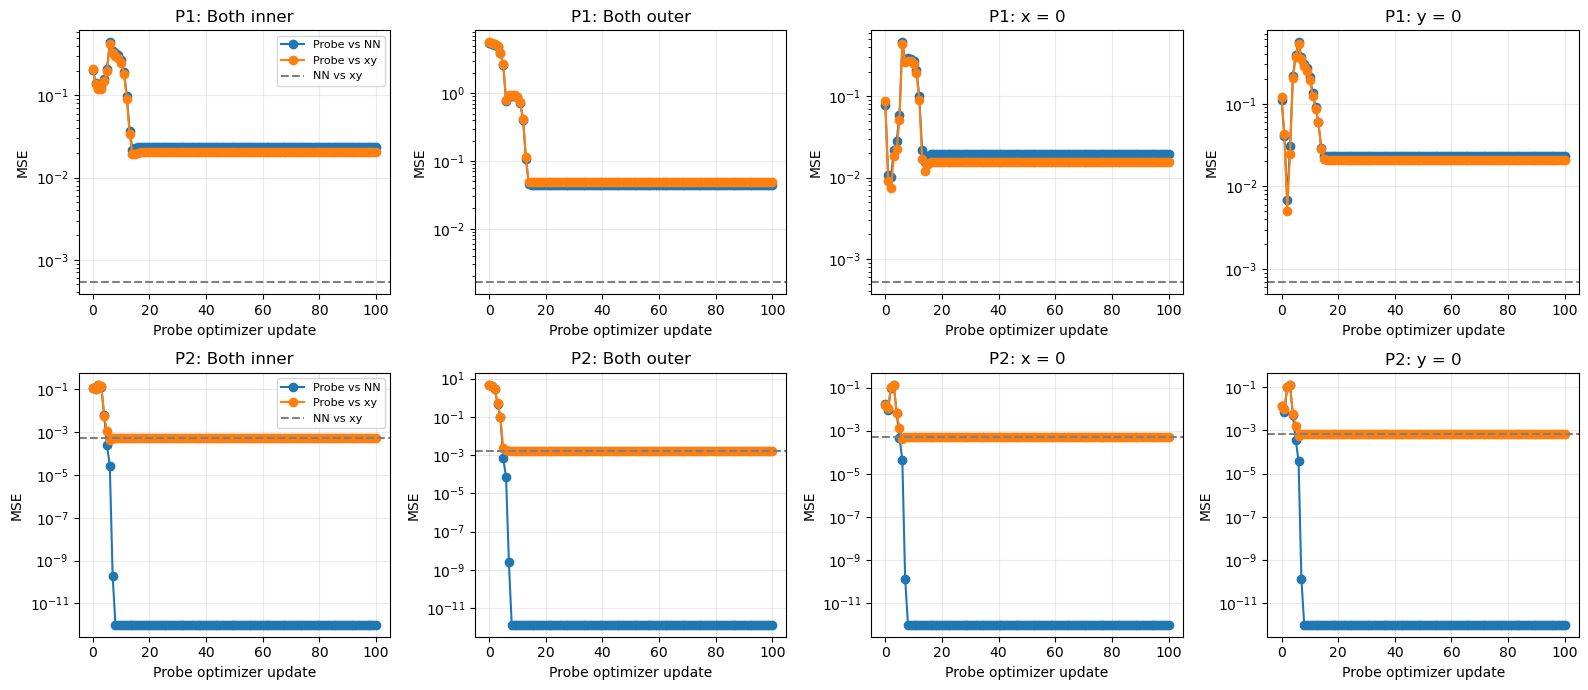

In [7]:
case_inputs = make_cases(1024, seed=456)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
with torch.no_grad():
    for col, (case_name, inputs) in enumerate(case_inputs.items()):
        features = model.activations(inputs)
        nn_prediction, truth = model(inputs), product(inputs)
        baseline = loss_fn(nn_prediction, truth).item()
        for row, (_, _, states) in enumerate(probe_runs):
            updates, fidelity, task_error = [], [], []
            for step, state in states:
                prediction = nn.functional.linear(features[row], state["weight"], state["bias"])
                updates.append(step)
                fidelity.append(max(loss_fn(prediction, nn_prediction).item(), 1e-12))
                task_error.append(max(loss_fn(prediction, truth).item(), 1e-12))
            ax = axes[row, col]
            ax.semilogy(updates, fidelity, "o-", label="Probe vs NN")
            ax.semilogy(updates, task_error, "o-", label="Probe vs xy")
            ax.axhline(max(baseline, 1e-12), color="gray", ls="--", label="NN vs xy")
            ax.set(title=f"P{row + 1}: {case_name}", xlabel="Probe optimizer update", ylabel="MSE")
            ax.grid(alpha=0.25)
            if col == 0:
                ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### What the aggregate error numbers mean

Every entry in the next aggregate table is **mean squared error**, $\mathrm{MSE}(a,b)=\frac{1}{N}\sum_i(a_i-b_i)^2$, across all sampled inputs in that row. Lower is better; zero means exact agreement. For example, **NN−xy MSE** averages the network's squared error against the true product. An MSE of 0.001 corresponds to RMSE $\sqrt{0.001} \approx 0.0316$ in output units; it does not mean every prediction is off by 0.001.

**P1−NN / P2−NN** measure fidelity to the network. **P1−xy / P2−xy** measure accuracy on multiplication. A probe can match a network that still makes mistakes. These aggregate errors are different from the **actual per-example predictions** in the five-example tables below (`xy`, `NN`, `P1`, `P2`), which are preserved.

In [8]:
evaluation_cases = {"Whole square": test_x, **make_cases(1024, seed=456)}
print("All aggregate entries below are MSE (mean squared error), not predictions.")
print(f"{'Case':<16} {'NN−xy MSE':>12} {'P1−NN MSE':>12} {'P1−xy MSE':>12} "
      f"{'P2−NN MSE':>12} {'P2−xy MSE':>12}")

with torch.no_grad():
    for name, inputs in evaluation_cases.items():
        target = product(inputs)
        prediction = model(inputs)
        h1, h2 = model.activations(inputs)
        p1, p2 = probe1(h1), probe2(h2)
        errors = [loss_fn(a, b).item() for a, b in [
            (prediction, target), (p1, prediction), (p1, target),
            (p2, prediction), (p2, target),
        ]]
        print(f"{name:<16}" + "".join(f"{error:12.6f}" for error in errors))

    print("\nFive-example predictions (same inputs as the activation printout):")
    for name, inputs in examples.items():
        h1, h2 = model.activations(inputs)
        print(f"\n{name}")
        print("     x       y      xy      NN      P1      P2")
        rows = torch.cat([inputs, product(inputs), model(inputs),
                          probe1(h1), probe2(h2)], dim=1)
        for row in rows:
            print(" ".join(f"{value:+7.3f}" for value in row.tolist()))

All aggregate entries below are MSE (mean squared error), not predictions.
Case                NN−xy MSE    P1−NN MSE    P1−xy MSE    P2−NN MSE    P2−xy MSE
Whole square        0.000724    0.022701    0.023284    0.000000    0.000724
Both inner          0.000533    0.023750    0.020249    0.000000    0.000532
Both outer          0.001625    0.044697    0.048898    0.000000    0.001625
x = 0               0.000518    0.019363    0.015424    0.000000    0.000518
y = 0               0.000692    0.023036    0.020794    0.000000    0.000692

Five-example predictions (same inputs as the activation printout):

Both inner
     x       y      xy      NN      P1      P2
 -0.408  +0.033  -0.014  -0.059  +0.093  -0.059
 -0.497  +0.377  -0.187  -0.225  -0.114  -0.225
 -0.852  +0.733  -0.625  -0.620  -0.562  -0.620
 -0.727  -0.795  +0.578  +0.585  +0.691  +0.585
 -0.632  +0.453  -0.286  -0.314  -0.223  -0.314

Both outer
     x       y      xy      NN      P1      P2
 +1.854  +1.593  +2.953  +2.896 

## Final surfaces over the original inputs

These panels compare $xy$, the frozen network, and the two final probes composed with their hidden layers. All use the same grid, axes, and output limits.

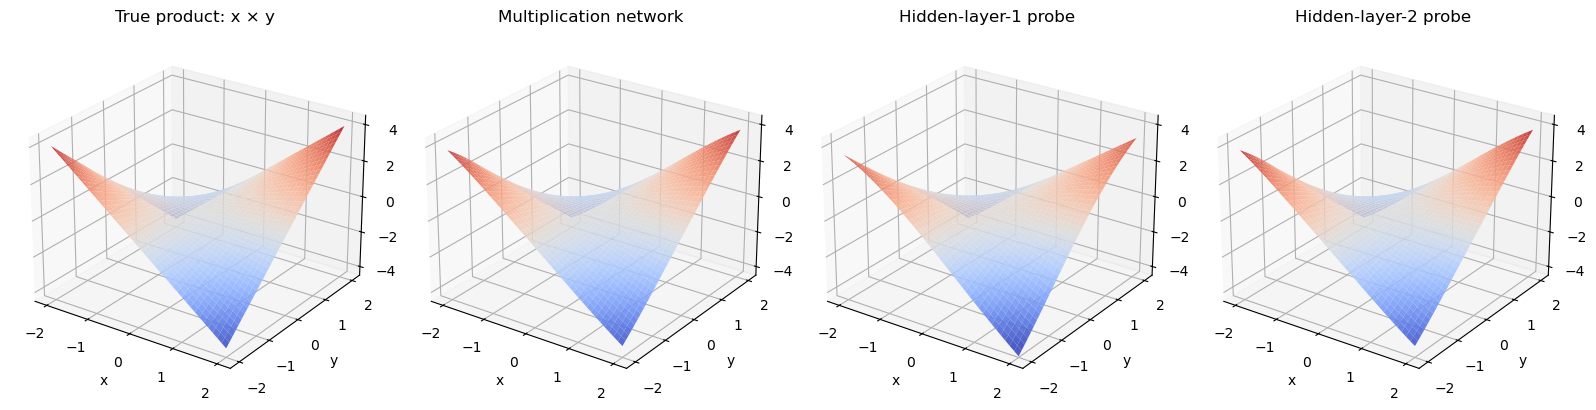

In [9]:
axis = torch.linspace(-2, 2, 81)
xx, yy = torch.meshgrid(axis, axis, indexing="xy")
grid = torch.stack([xx.flatten(), yy.flatten()], dim=1)

with torch.no_grad():
    h1, h2 = model.activations(grid)
    surfaces = [product(grid), model(grid), probe1(h1), probe2(h2)]
    surfaces = [surface.reshape(xx.shape).numpy() for surface in surfaces]

fig = plt.figure(figsize=(16, 4))
for i, (title, surface) in enumerate(zip(
    ["True product: x × y", "Multiplication network", "Hidden-layer-1 probe", "Hidden-layer-2 probe"],
    surfaces,
)):
    ax = fig.add_subplot(1, 4, i + 1, projection="3d")
    ax.plot_surface(xx.numpy(), yy.numpy(), surface, cmap="coolwarm",
                    vmin=-4, vmax=4, linewidth=0, alpha=0.9)
    ax.set(xlabel="x", ylabel="y", zlabel="Output", title=title, zlim=(-4.5, 4.5))
    ax.view_init(elev=25, azim=-55)
fig.tight_layout()
plt.show()


Try changing the seed, number of training steps, or hidden activation and rerunning all cells. Compare overall test error, behavior along the zero-input axes, and first-layer probe fidelity. Probe weights depend on the learned representation and can change across runs, even when the output surface is similar.